# Joint HPP and data-center sizing: native Parallel EGO
Use **hydesign_clean** and Run All. The original Parallel EGO chooses HPP sizes and installed IT capacity.
Each candidate uses constant facility demand = IT capacity × PUE. The unchanged EMS enforces hourly reliability.
The outer objective maximizes annual DC revenue minus annualized DC and HPP cost.

The time limit covers the search, including startup. Independent final validation runs afterwards.
Results are validated feasible incumbents, not certified global optima.

Shared infrastructure is always included: G_proxy_MW = facility_load_mw + rated b_P,
without efficiency correction. Native shared_cost uses BOS 119,940 EUR/MW and
land 300,000 EUR/km2 times max(Awpp, Apvp); public-grid cost is zero.
This capacity proxy is not a detailed electrical-network design. Shared CAPEX
is annualized using the HPP rates (6%) and economic lifetime (25 years).

Battery economics include one full replacement in year 15, discounted at the
battery WACC (6%) and annualized across the HPP economic lifetime (25 years).
CAPEX_b and CAPEX_hpp remain year-0 investment only. The new replacement fields
are expenditures in EUR, not EUR/year. There is no physical degradation, price
reduction or salvage value; hourly dispatch and reliability are unchanged.


In [1]:
import os
os.environ['OPENMDAO_REPORTS'] = '0'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import hydesign
from hydesign.sizing_native_joint_hpp_sizing_base import (
    read_configuration, run_native_joint_hpp_sizing, print_results, plot_history,
)
from hydesign.assembly.hpp_assembly_simple_datacenter_joint_hpp_sizing_base import IT_NAME

repo = Path(hydesign.__file__).resolve().parent.parent
config_path = repo / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'
print('Python:', sys.executable)
print('Repository:', repo)


Python: c:\Users\loict\anaconda3\envs\hydesign_clean\python.exe
Repository: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign


## Configuration
YAML supplies the defaults; these overrides apply only to this run. Change `var_type` between `design` and `fixed`.
Design variables use `limits`; fixed variables use `value`. All fixed evaluates once.
IT bounds initially correspond to the existing 1–50 MW facility range at the chosen PUE.
The shared battery fluctuation penalty and financial assumptions are retained.


In [2]:
config = read_configuration(config_path)

# DC settings
config['reliability_target'] = 0.99
config['pue'] = 1.15

# Native EGO settings (other defaults remain in YAML)
config['hpp_sizing_time_limit_seconds'] = 60
config['n_doe'] = 40
config['n_seed'] = 1
config['n_clusters'] = 4
config['n_procs'] = 2
config['max_iter'] = 30
config['hpp_sizing_output_dir'] = str(repo / 'joint_hpp_dc_sizing_runs')

# The five sizing variables; geometry and technology remain fixed.
variables = config['variables']
variables['Nwt'].update(var_type='design', types='int', limits=[0, 60], value=20)
variables['solar_MW [MW AC]'].update(var_type='design', types='float', limits=[0, 300], value=180)
variables['b_P [MW]'].update(var_type='design', types='float', limits=[0, 80], value=25)
variables['b_E_h [h]'].update(var_type='design', types='float', limits=[1, 24], value=8)
variables[IT_NAME] = dict(
    var_type='design', types='float', value=16 / config['pue'],
    limits=[config['facility_load_min_mw'] / config['pue'],
            config['facility_load_max_mw'] / config['pue']],  # MW IT; edit these bounds
)
print('Outer budget [s]:', config['hpp_sizing_time_limit_seconds'])
print('Reliability target:', config['reliability_target'], '| PUE:', config['pue'])
display(pd.DataFrame(variables).T)


Outer budget [s]: 60
Reliability target: 0.99 | PUE: 1.15


,var_type,value,limits,types
clearance [m],fixed,35,NaN,NaN
sp [W/m2],fixed,300,NaN,NaN
p_rated [MW],fixed,5,NaN,NaN
Nwt,design,20,"[0, 60]",int
wind_MW_per_km2 [MW/km2],fixed,7,NaN,NaN
solar_MW [MW AC],design,180,"[0, 300]",float
surface_tilt [deg],fixed,42,NaN,NaN
surface_azimuth [deg],fixed,180,NaN,NaN
DC_AC_ratio,fixed,1.25,NaN,NaN
b_P [MW],design,25,"[0, 80]",float


## Run optimization
Each run has its own folder. Completed checkpoints survive a time limit or notebook interruption;
unresolved solves are not accepted as feasible. Search progress is in the saved native EGO log.


In [3]:
result = run_native_joint_hpp_sizing(config_path, overrides=config)


Joint native EGO results: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\joint_hpp_dc_sizing_runs\20261102_164428_2debe2fd_joint_hpp_sizing_base
Outer limit [s]: 60
Search stopped: TIME_LIMIT -- independently validating value-ranked candidates.


## Results
Economics are actual unshifted EUR/year; the shifted EGO score is only an optimization interface.
The JSON summary contains the full design, economics, validation and solver metadata.


In [4]:
print_results(result)


Final status: VALIDATED_FEASIBLE_INCUMBENT | Search: TIME_LIMIT

HPP
Turbines: 37 | Wind: 185.000 MW | PV: 277.365 MW AC
Battery: 58.972 MW / 1007.323 MWh / 17.081 h

Data center
IT: 26.4118 MW IT | Facility: 30.3736 MW | PUE: 1.15
Annual IT demand: 231,367.365 MWh | Served: 231,202.582 MWh
Facility EENS: 189.500 MWh | LOLH: 41.0 h
Reliability: 99.53196% | Target: 99%
IT capacity bounds: interior

Economics
Initial battery CAPEX: 68,247,992.08 EUR
Battery replacement (year 15): 68,247,992.08 EUR
Discounted battery replacement: 28,477,502.56 EUR at year 0
Annualized battery CAPEX / cost: 7,566,518.01 / 7,566,518.01 EUR/year
Shared capacity proxy (facility + rated battery): 89.346 MW
CAPEX_sh_fixed: 10,716,099.47 EUR
CAPEX_sh_land: 7,928,571.43 EUR
CAPEX_sh: 18,644,670.90 EUR
annualized_cost_shared: 1,458,511.42 EUR/year
Revenue_dc: 924,810,326.54 EUR/year (924.8103 MEUR/year)
annualized_cost_dc: 131,549,782.84 EUR/year (131.5498 MEUR/year)
annualized_cost_hpp: 33,283,290.11 EUR/year (33

## Optimization history
The incumbent curve maximizes system value. Rejected or interrupted designs have no valid economic result;
the capacity plot marks them along its lower edge, not as zero-valued designs.
Plots are also saved automatically in the run folder.


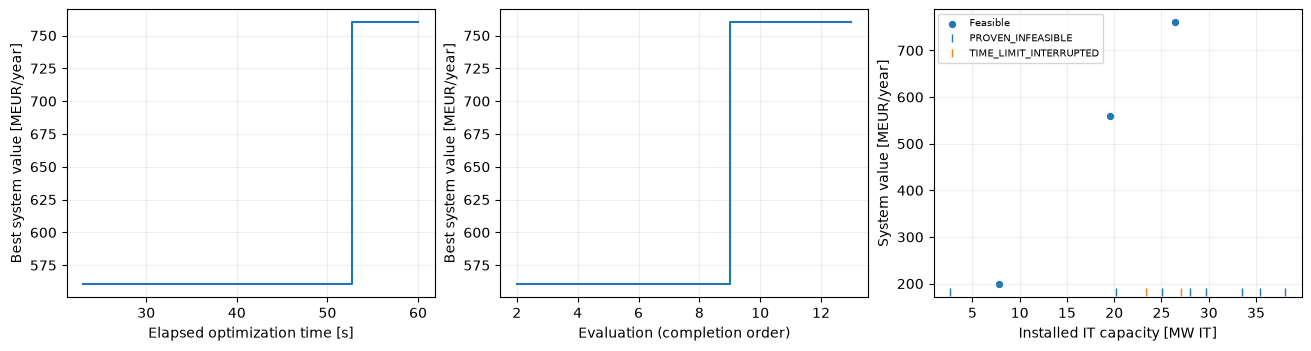

In [5]:
fig = plot_history(result)
plt.show()
